In [1]:
%pip install kagglehub --quiet

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [ ]:
import kagglehub

path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 22.0M/22.0M [00:01<00:00, 14.2MB/s]

Extracting files...


Path to dataset files: C:\Users\Admin\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1


In [ ]:
import os

for dirpath, dirnames, filenames in os.walk(path):
    depth = dirpath.replace(path, "").count(os.sep)
    if depth <= 2:  
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath)}/")
        if filenames:
            print(f"{indent}  └── файлов: {len(filenames)}, примеры: {filenames[:3]}")

1/
  └── файлов: 4, примеры: ['t10k-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 'train-images.idx3-ubyte']
  t10k-images-idx3-ubyte/
    └── файлов: 1, примеры: ['t10k-images-idx3-ubyte']
  t10k-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['t10k-labels-idx1-ubyte']
  train-images-idx3-ubyte/
    └── файлов: 1, примеры: ['train-images-idx3-ubyte']
  train-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['train-labels-idx1-ubyte']


In [ ]:
import os
import struct
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

ROOT = path  # путь к данным, который вернул kagglehub

def read_idx_images(path):
    """Читает IDX-файл с изображениями → массив (N, rows*cols)."""
    with open(path, 'rb') as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        # Проверяем магическое число (2051 = 0x00000803)
        assert magic == 2051, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
        data = data.reshape(n, rows * cols)
    return data.astype(np.float32)

def read_idx_labels(path):
    """Читает IDX-файл с метками → массив (N,)."""
    with open(path, 'rb') as f:
        magic, n = struct.unpack(">II", f.read(8))
        # Проверяем магическое число (2049 = 0x00000801)
        assert magic == 2049, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(int)

def load_mnist_idx(root_dir):
    """
    Загружает MNIST из IDX-файлов в стиле MedMNIST:
    возвращает (X_train, y_train, X_val, y_val, X_test, y_test).

    MNIST: 60000 train + 10000 test. Отделяем 10% от train под validation.
    """
    root = Path(root_dir)

    def find_file(*candidates):
        for name in candidates:
            p = root / name
            if p.exists():
                return p
            for sub in root.rglob(name):
                return sub
        raise FileNotFoundError(
            f"Не найден файл среди: {candidates} в {root_dir}"
        )

    train_images = find_file(
        "train-images.idx3-ubyte",
        "train-images-idx3-ubyte",
    )
    train_labels = find_file(
        "train-labels.idx1-ubyte",
        "train-labels-idx1-ubyte",
    )
    test_images = find_file(
        "t10k-images.idx3-ubyte",
        "t10k-images-idx3-ubyte",
    )
    test_labels = find_file(
        "t10k-labels.idx1-ubyte",
        "t10k-labels-idx1-ubyte",
    )

    print(f"Train images: {train_images}")
    print(f"Train labels: {train_labels}")
    print(f"Test  images: {test_images}")
    print(f"Test  labels: {test_labels}")

    X_train_full = read_idx_images(train_images)
    y_train_full = read_idx_labels(train_labels)
    X_test       = read_idx_images(test_images)
    y_test       = read_idx_labels(test_labels)

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.1,
        random_state=42,
        stratify=y_train_full,
    )

    X_train = X_train / 255.0
    X_val   = X_val   / 255.0
    X_test  = X_test  / 255.0

    print(f"\nTrain:      X={X_train.shape}, y={y_train.shape}")
    print(f"Validation: X={X_val.shape},   y={y_val.shape}")
    print(f"Test:       X={X_test.shape},  y={y_test.shape}")

    return X_train, y_train, X_val, y_val, X_test, y_test

## Загрузка данных

In [5]:
X_train, y_train, X_val, y_val, X_test, y_test = load_mnist_idx(ROOT)

Train images: C:\Users\Admin\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1\train-images.idx3-ubyte
Train labels: C:\Users\Admin\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1\train-labels.idx1-ubyte
Test  images: C:\Users\Admin\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1\t10k-images.idx3-ubyte
Test  labels: C:\Users\Admin\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1\t10k-labels.idx1-ubyte

Train:      X=(54000, 784), y=(54000,)
Validation: X=(6000, 784),   y=(6000,)
Test:       X=(10000, 784),  y=(10000,)


## Знакомство с данными

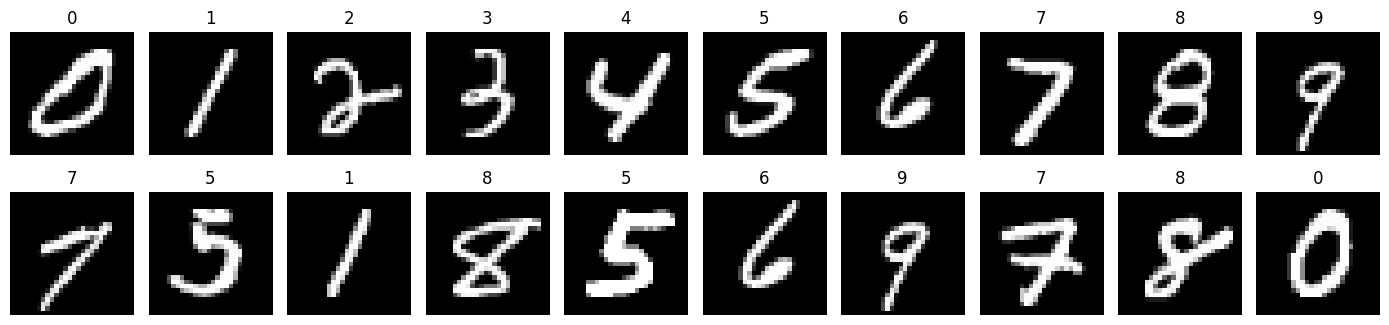

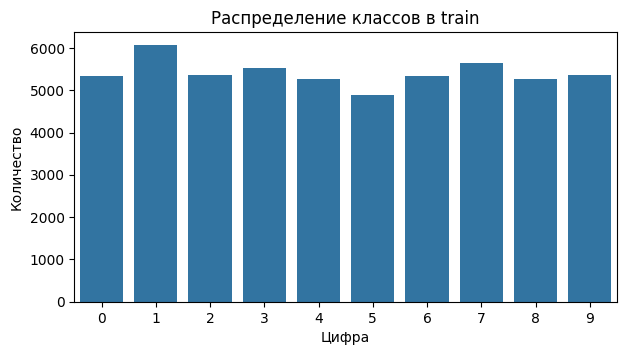

In [6]:
import time
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))
for digit, ax in zip(range(10), axes[0]):
    idx = np.where(y_train == digit)[0][0]
    ax.imshow(X_train[idx].reshape(28, 28), cmap='gray')
    ax.set_title(digit)
    ax.axis('off')
for i, ax in enumerate(axes[1]):
    ax.imshow(X_train[i + 10].reshape(28, 28), cmap='gray')
    ax.set_title(y_train[i + 10])
    ax.axis('off')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 3.5))
sns.countplot(x=y_train)
plt.title('Распределение классов в train')
plt.xlabel('Цифра')
plt.ylabel('Количество')
plt.show()

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

models = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    'MLP': MLPClassifier(hidden_layer_sizes=(128,), early_stopping=True, max_iter=50, random_state=42),
}

rows = []
fitted = {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - start
    fitted[name] = model
    rows.append({
        'Модель': name,
        'Accuracy (val)': accuracy_score(y_val, model.predict(X_val)),
        'Accuracy (test)': accuracy_score(y_test, model.predict(X_test)),
        'Время обучения, с': fit_time,
    })
    print(name, '-> готово за', round(fit_time, 1), 'с')

c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression -> готово за 33.9 с
Random Forest -> готово за 14.7 с
MLP -> готово за 49.1 с


### Результаты

                     Accuracy (val)  Accuracy (test)  Время обучения, с
Модель                                                                 
Logistic Regression          0.9218           0.9243            33.9141
Random Forest                0.9658           0.9696            14.6685
MLP                          0.9747           0.9780            49.0914


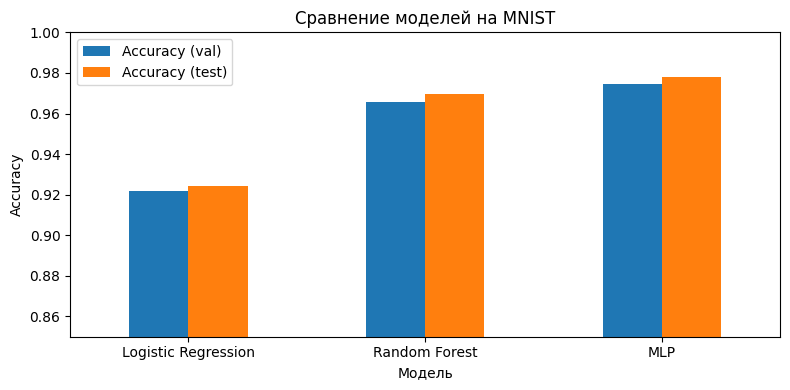

In [8]:
results = pd.DataFrame(rows).set_index('Модель').round(4)
print(results)

results[['Accuracy (val)', 'Accuracy (test)']].plot(kind='bar', figsize=(8, 4), ylim=(0.85, 1.0))
plt.ylabel('Accuracy')
plt.title('Сравнение моделей на MNIST')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Лучшая модель

Лучшая модель по validation: MLP
Accuracy на test: 0.978

              precision    recall  f1-score   support

           0     0.9838    0.9888    0.9863       980
           1     0.9912    0.9903    0.9907      1135
           2     0.9805    0.9729    0.9767      1032
           3     0.9764    0.9832    0.9798      1010
           4     0.9717    0.9796    0.9757       982
           5     0.9753    0.9753    0.9753       892
           6     0.9851    0.9666    0.9758       958
           7     0.9757    0.9767    0.9762      1028
           8     0.9644    0.9723    0.9683       974
           9     0.9742    0.9722    0.9732      1009

    accuracy                         0.9780     10000
   macro avg     0.9778    0.9778    0.9778     10000
weighted avg     0.9780    0.9780    0.9780     10000



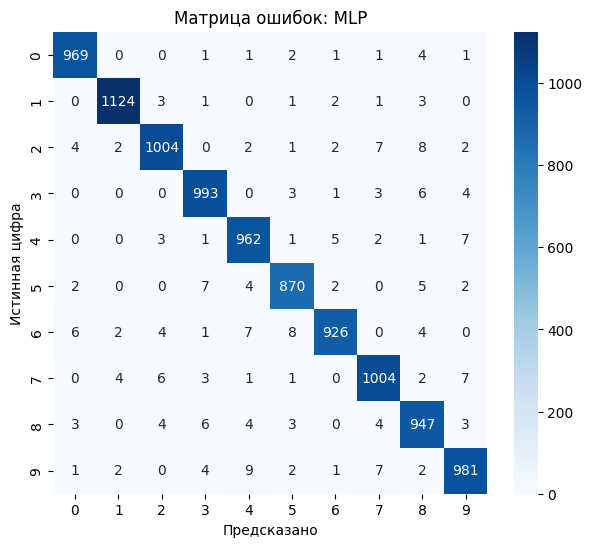

In [ ]:
best_name = results['Accuracy (val)'].idxmax()
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)

print('Лучшая модель по validation:', best_name)
print('Accuracy на test:', round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, digits=4))

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Предсказано')
plt.ylabel('Истинная цифра')
plt.title(f'Матрица ошибок: {best_name}')
plt.show()